Write a Python script using pandas and scikit-learn to load a dataset, perform a
70/30 train/test split, and apply standard scaling (StandardScaler) to the feature columns. Give a proper copy paste code, without errors. So that when i run, the output will come.

In [1]:
pip install pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:

import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["target"] = iris.target

print("Original Dataset:")
print(df.head())

X = df.drop("target", axis=1)
y = df["target"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X.columns,
    index=X_test.index
)

print("\nTraining Features Shape:", X_train_scaled.shape)
print("Testing Features Shape:", X_test_scaled.shape)

print("\nScaled Training Features (First 5 Rows):")
print(X_train_scaled.head().round(3))

print("\nScaled Testing Features (First 5 Rows):")
print(X_test_scaled.head().round(3))

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nStandard scaling and train/test split completed successfully!")


Original Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Training Features Shape: (105, 4)
Testing Features Shape: (45, 4)

Scaled Training Features (First 5 Rows):
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
98              -0.900            -1.220             -0.442            -0.137
68               0.380            -1.880              0.403             0.380
19              -0.900             1.637             -1.287            -1.170
143           

Using matplotlib and seaborn, write a function that takes a pandas DataFrame and a column name as input, and plots both a boxplot and a scatter plot to visually identify outliers and distribution patterns.

In [4]:
pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


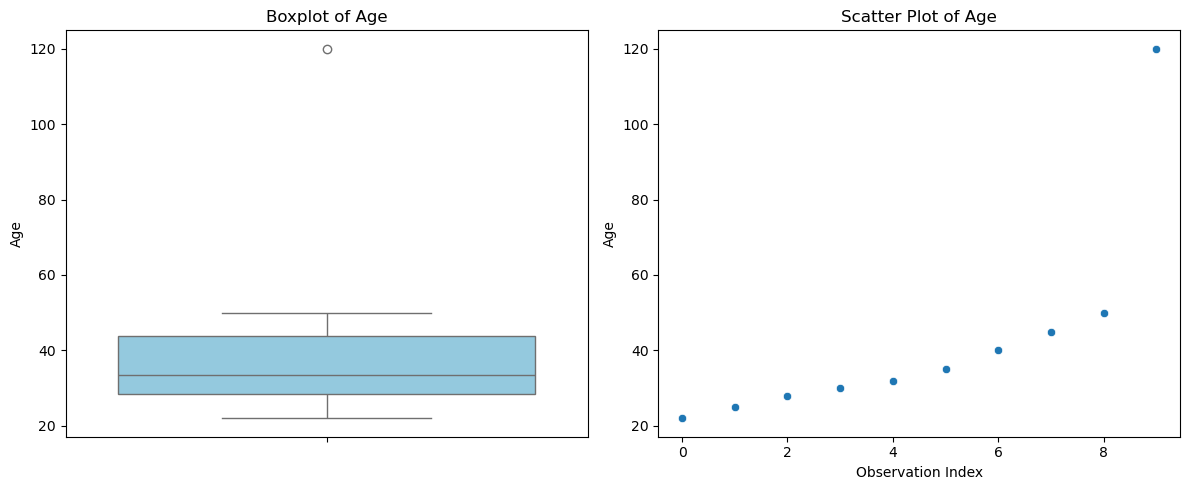

In [5]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def plot_outliers(df, column_name):
    if column_name not in df.columns:
        raise ValueError(f"Column '{column_name}' not found in DataFrame.")

    if not pd.api.types.is_numeric_dtype(df[column_name]):
        raise TypeError(f"Column '{column_name}' must contain numeric data.")
    data = df[column_name].replace([float("inf"), float("-inf")], float("nan")).dropna()

    if data.empty:
        raise ValueError(f"Column '{column_name}' has no valid numeric data.")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.boxplot(y=data, ax=axes[0], color="skyblue")
    axes[0].set_title(f"Boxplot of {column_name}")
    axes[0].set_ylabel(column_name)

    sns.scatterplot(x=range(len(data)), y=data.values, ax=axes[1])
    axes[1].set_title(f"Scatter Plot of {column_name}")
    axes[1].set_xlabel("Observation Index")
    axes[1].set_ylabel(column_name)
    plt.tight_layout()
    plt.show()

df = pd.DataFrame({
    "Age": [22, 25, 28, 30, 32, 35, 40, 45, 50, 120],
    "Salary": [25000, 30000, 35000, 40000, 45000,
               50000, 55000, 60000, 65000, 200000]
})

# Call the function
plot_outliers(df, "Age")


Implement a linear regression model using scikit-learn's LinearRegression on a housing dataset. Calculate and print the Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R' score on the test set.

In [6]:
pip install pandas numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [7]:

import pandas as pd
import numpy as np

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("First 5 rows of the dataset:")
print(df.head())

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)


y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nLinear Regression Model Evaluation")
print("----------------------------------")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"R² Score:                       {r2:.4f}")

print("\nModel training and evaluation completed successfully!")


First 5 rows of the dataset:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Linear Regression Model Evaluation
----------------------------------
Root Mean Squared Error (RMSE): 0.7284
Mean Absolute Error (MAE):      0.5272
R² Score:                       0.5958

Model training and evaluation completed successfully!


Write a Python program to load the Iris dataset, train a LogisticRegression model, and output the predicted classes for the test dataset.

In [8]:

import pandas as pd

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=200)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Predicted Classes:")
print(y_pred)

results = pd.DataFrame({
    "Actual Class": y_test,
    "Predicted Class": y_pred
})

print("\nActual vs Predicted Classes:")
print(results.to_string(index=False))

# Step 8: Display class names
print("\nPredicted Iris Species:")
print(iris.target_names[y_pred])


Predicted Classes:
[2 1 1 1 2 2 1 1 0 2 0 0 2 2 0 2 1 0 0 0 1 0 1 2 2 1 1 1 1 0 2 2 1 0 2 0 0
 0 0 2 1 0 1 2 1]

Actual vs Predicted Classes:
 Actual Class  Predicted Class
            2                2
            1                1
            2                1
            1                1
            2                2
            2                2
            1                1
            1                1
            0                0
            2                2
            0                0
            0                0
            2                2
            2                2
            0                0
            2                2
            1                1
            0                0
            0                0
            0                0
            1                1
            0                0
            1                1
            2                2
            2                2
            1                1
            1        

Implement a K-Nearest Neighbors (KNN) classifier with n_neighbors=5. After training and testing the model, write the code to compute and display its confusion matrix using scikit-learn utilities.

Confusion Matrix:
[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]

Model Accuracy: 0.9778


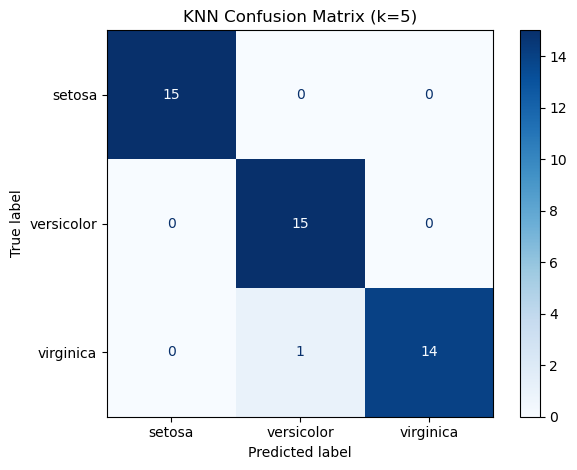

In [9]:

import pandas as pd

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

model = KNeighborsClassifier(n_neighbors=5)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(accuracy, 4))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

display.plot(cmap="Blues")
plt.title("KNN Confusion Matrix (k=5)")
plt.tight_layout()
plt.show()


Write a script to compare a single Decision Tree Classifier against a Random Forest Classifier on a binary classification dataset. Print the accuracy score of both models to determine which performed better.

In [10]:

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

dt_model = DecisionTreeClassifier(random_state=42)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)
rf_accuracy = accuracy_score(y_test, rf_pred)


print("Model Accuracy Comparison")
print("-------------------------")
print(f"Decision Tree Accuracy: {dt_accuracy:.4f}")
print(f"Random Forest Accuracy: {rf_accuracy:.4f}")

print("\nComparison Result:")

if dt_accuracy > rf_accuracy:
    print("Decision Tree performed better.")
elif rf_accuracy > dt_accuracy:
    print("Random Forest performed better.")
else:
    print("Both models achieved the same accuracy.")


Model Accuracy Comparison
-------------------------
Decision Tree Accuracy: 0.9181
Random Forest Accuracy: 0.9357

Comparison Result:
Random Forest performed better.


Given a set of true labels and predicted labels, write code to manually calculate or use scikit-learn to extract the precision, recall, and F1-score for a specific target class without using the full classification_report.

In [11]:

from sklearn.metrics import precision_score, recall_score, f1_score


y_true = [0, 1, 2, 1, 2, 0, 1, 2, 0, 1]
y_pred = [0, 1, 1, 1, 2, 0, 2, 2, 1, 1]

target_class = 1

precision = precision_score(
    y_true, y_pred, labels=[target_class],
    average="micro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, labels=[target_class],
    average="micro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, labels=[target_class],
    average="micro", zero_division=0
)

print(f"Target Class: {target_class}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")


Target Class: 1
Precision: 0.6000
Recall:    0.7500
F1-Score:  0.6667


Implement a 5-fold cross-validation routine using KFold and cross_val_score to evaluate the stability of a Ridge regression model on a continuous target variable.

In [12]:

import numpy as np

from sklearn.datasets import load_diabetes
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


data = load_diabetes()

X = data.data
y = data.target

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# Scaling is fitted separately within each training fold.
model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

scores = cross_val_score(
    model,
    X,
    y,
    cv=kf,
    scoring="r2"
)


print("Ridge Regression: 5-Fold Cross-Validation")
print("------------------------------------------")

for i, score in enumerate(scores, start=1):
    print(f"Fold {i} R² Score: {score:.4f}")

mean_score = np.mean(scores)
std_score = np.std(scores)

print("\nCross-Validation Results")
print("------------------------")
print(f"Mean R² Score: {mean_score:.4f}")
print(f"Standard Deviation: {std_score:.4f}")


if std_score < 0.05:
    print("Stability: Relatively consistent scores.")
else:
    print("Stability: Scores show some variation across folds.")


Ridge Regression: 5-Fold Cross-Validation
------------------------------------------
Fold 1 R² Score: 0.4541
Fold 2 R² Score: 0.5717
Fold 3 R² Score: 0.3919
Fold 4 R² Score: 0.5832
Fold 5 R² Score: 0.3944

Cross-Validation Results
------------------------
Mean R² Score: 0.4791
Standard Deviation: 0.0834
Stability: Scores show some variation across folds.


Write a Python snippet utilizing GridSearchCV to find the optimal hyperparameters for a Random Forest Classifier. Search across _estimators (50, 100, 200)) and max_depth ([None, 10, 20]).

In [13]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


rf = RandomForestClassifier(random_state=42)

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:",
      round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
print("Test Accuracy:", round(test_accuracy, 4))

Best Hyperparameters: {'max_depth': None, 'n_estimators': 100}
Best Cross-Validation Accuracy: 0.9725
Test Accuracy: 0.9357


Create a complete scikit-learn Pipeline that chains a MinMaxScaler preprocessing step with a LogisticRegression classifier, then fit the entire pipeline on training data and evaluate it on test data.

In [14]:

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])


pipeline.fit(X_train, y_train)


y_pred = pipeline.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)

print("Pipeline Training and Evaluation")
print("--------------------------------")
print(f"Test Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))


sample_prediction = pipeline.predict(X_test[:1])

print("Sample Predicted Class:", data.target_names[sample_prediction[0]])
print("Sample Actual Class:", data.target_names[y_test.iloc[0]] if hasattr(y_test, "iloc") else data.target_names[y_test[0]])


Pipeline Training and Evaluation
--------------------------------
Test Accuracy: 0.9474

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.88      0.93        64
      benign       0.93      0.99      0.96       107

    accuracy                           0.95       171
   macro avg       0.96      0.93      0.94       171
weighted avg       0.95      0.95      0.95       171

Sample Predicted Class: malignant
Sample Actual Class: malignant
